In [1]:
import os
os.environ.pop("PYTHONPATH", None)

import sys
sys.path = [
    p for p in sys.path
    if "/opt/software-current/" not in p
]

import regex
print("regex:", regex.__file__)

regex: /mnt/home/linpaul1/Documents/SPROUT/.venv/lib/python3.13/site-packages/regex/__init__.py


In [2]:
import pandas as pd

df = pd.read_parquet("../../data/unsplash/clip_train.parquet")
collections_df = pd.read_csv("../../data/unsplash/collections.tsv000", sep="\t")

board_titles = (
    collections_df
    .groupby("photo_id")["collection_title"]
    .apply(lambda x: ", ".join(x.dropna().astype(str).unique()))
    .rename("collection_title")
)

df = df.merge(board_titles, on="photo_id", how="left")

unique_collections = (
    collections_df[
        ["collection_id", "collection_title"]
    ]
    .drop_duplicates("collection_id")
    .reset_index(drop=True)
)

df["image_path"] = [f"../../data/unsplash/{i}" for i in df["image_path"]]

In [3]:
inject_df = pd.read_csv("../../data/small/metadata.csv")

In [4]:
for idx, row in enumerate(inject_df[:10].iterrows()):
    new_row = pd.DataFrame({
        "photo_id": [f"laptop_twee_{idx}"],
        "image_path": [f"../../data/small/{row[1]["image_path"]}"],
        "caption": [row[1]["caption"]],
        "collection_title": ["laptop twee"]
    })

    df = pd.concat([df, new_row], ignore_index=True)

In [5]:
import torch
from transformers import AutoModel, AutoProcessor
from PIL import Image
import torch.nn.functional as F

MODEL_NAME = "google/siglip2-base-patch16-224"

device = "cuda" if torch.cuda.is_available() else "cpu"

embed_model = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()

embed_processor = AutoProcessor.from_pretrained(MODEL_NAME)

/mnt/home/linpaul1/Documents/SPROUT/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.
Loading weights: 100%|██████████| 408/408 [00:00<00:00, 643.55it/s]


In [6]:
def embed_images_batch(image_paths, batch_size: int = 1024):
    embeddings = []


    for start in range(0, len(image_paths), batch_size):
        batch_paths = image_paths[start:start + batch_size]

        images = []
        for path in batch_paths:
            with Image.open(path) as img:
                images.append(img.convert("RGB"))

        inputs = embed_processor(images=images, return_tensors="pt").to(device)

        with torch.inference_mode():
            output = embed_model.get_image_features(**inputs)
            embedding = output.pooler_output
            embedding = F.normalize(embedding, p=2, dim=-1)

        embeddings.append(embedding)

    # return embedding.squeeze(0)
    return torch.cat(embeddings, dim=0)

def embed_text_batch(texts, batch_size: int = 1024):
    embeddings = []

    for start in range(0, len(texts), batch_size):

        inputs = embed_processor(text=texts[start:start + batch_size],
            padding="max_length",            truncation=True,
 return_tensors="pt").to(device)

        with torch.inference_mode():
            output = embed_model.get_text_features(**inputs)
            embedding = output.pooler_output
            embedding = F.normalize(embedding, p=2, dim=-1)

        embeddings.append(embedding)

    return torch.cat(embeddings, dim=0)

from sentence_transformers import SentenceTransformer

st = SentenceTransformer(
    "all-MiniLM-L6-v2",
    device=device
)

def embed_text_batch_st(texts, batch_size: int = 1024):
    return st.encode(
        texts,
        batch_size=batch_size,
        convert_to_tensor=True,
        normalize_embeddings=True,
        show_progress_bar=True
    )

def embed_post_batch(df, batch_size=1024):
    image_paths = df["image_path"].astype(str).tolist()
    image_embeddings = embed_images_batch(image_paths, batch_size)

    captions = df["caption"].fillna("").astype(str).tolist()
    caption_embeddings = embed_text_batch_st(captions, batch_size)

    boards = df["collection_title"].fillna("").astype(str).tolist()
    board_embeddings = embed_text_batch_st(boards, batch_size)

    image_embeddings = F.normalize(image_embeddings, p=2, dim=-1)
    caption_embeddings = F.normalize(caption_embeddings, p=2, dim=-1)
    board_embeddings = F.normalize(board_embeddings, p=2, dim=-1)

    return image_embeddings, caption_embeddings, board_embeddings

def embed_collection_batch(df, batch_size=1024):
    titles = (
        df["collection_title"]
        .fillna("")
        .astype(str)
        .tolist()
    )

    return embed_text_batch(titles, batch_size)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 18130.49it/s]


In [ ]:
image_embeddings, caption_embeddings, board_embeddings = embed_post_batch(df)

In [8]:
photo_ids = df["photo_id"].tolist()

photo_to_idx = {
    photo_id: idx
    for idx, photo_id in enumerate(photo_ids)
}

collection_ids = unique_collections["collection_id"].tolist()

collection_to_idx = {
    collection_id: idx
    for idx, collection_id in enumerate(collection_ids)
}

In [9]:
import numpy as np
import torch
import collections

# Group photos by collection
groups = (
    collections_df[
        collections_df["photo_id"].isin(photo_to_idx)
    ]
    .drop_duplicates(["photo_id", "collection_id"])
    .groupby("collection_id")["photo_id"]
    .apply(lambda x: [photo_to_idx[p] for p in x])
)

# Create photo-to-photo edges
edges = []

for photos in groups:
    if len(photos) < 2:
        continue

    for i in range(len(photos)):
        for j in range(i + 1, len(photos)):
            edges.append((photos[i], photos[j]))
            edges.append((photos[j], photos[i]))

edge_index = torch.tensor(
    np.array(edges).T,
    dtype=torch.long
)

print("Edge index:", edge_index.shape)
print("Max index:", edge_index.max().item())
print("Num nodes:", post_embeddings.shape[0])

Edge index: torch.Size([2, 111771194])
Max index: 24996
Num nodes: 25007


In [10]:
import torch
import torch.nn.functional as F

def message_pass_batched(x, edge_index, alpha=0.3, batch_size=1_000_000):
    num_nodes, dim = x.shape
    device = x.device

    src, dst = edge_index
    num_edges = src.numel()

    # Accumulate on GPU
    neighbor_sum = torch.zeros_like(x)
    counts = torch.zeros(num_nodes, device=device, dtype=x.dtype)

    for start in range(0, num_edges, batch_size):
        end = min(start + batch_size, num_edges)

        s = src[start:end]
        d = dst[start:end]

        neighbor_sum.index_add_(0, d, x[s])

        counts.index_add_(
            0, d,
            torch.ones(d.numel(), device=device, dtype=x.dtype)
        )

    neighbor_mean = neighbor_sum / counts.clamp(min=1).unsqueeze(-1)

    out = (1 - alpha) * x + alpha * neighbor_mean

    return F.normalize(out, p=2, dim=-1)

out = message_pass_batched(
    post_embeddings.to("cuda"),
    edge_index.to("cuda"),
    alpha=0.3,
    batch_size=250_000
)

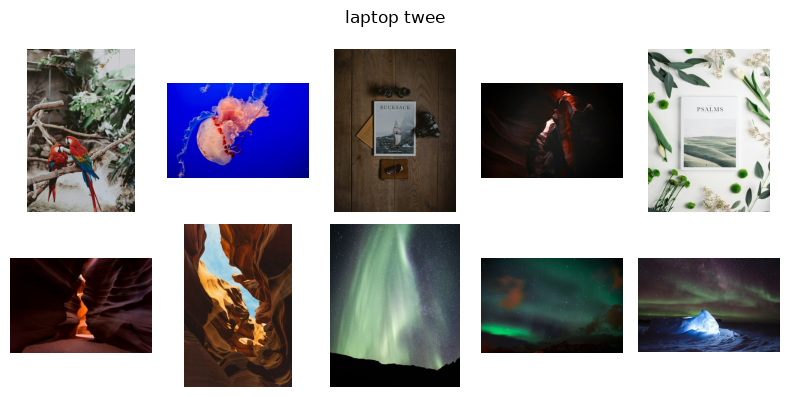

In [11]:
TESTS = ["laptop twee"]

for query in TESTS:
    query_embedding = embed_text_batch([query]).cpu().numpy()

    image_scores = out.cpu().numpy() @ query_embedding.T

    df[f"score_combined_{query}"] = (
        image_scores
    )

import matplotlib.pyplot as plt

for query in TESTS:
    top10 = df.sort_values(
        f"score_combined_{query}",
        ascending=False
    ).head(10)

    fig, axes = plt.subplots(2, 5, figsize=(8, 4))

    for i, ax in enumerate(axes.flat):
        row = top10.iloc[i]
        ax.imshow(Image.open(row["image_path"]))
        # ax.set_title(f"Rank {i + 1}", color="green" if row["class"] == query else "red")
        ax.axis("off")

    fig.suptitle(query)
    plt.tight_layout()
    plt.show()